In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import os
import glob

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
files = glob.glob('/kaggle/input/**/*.csv', recursive=True)

print("Available CSV files:")

for file in files:
    print(file)

Available CSV files:
/kaggle/input/datasets/niteshyadav3103/concrete-compressive-strength/Concrete Compressive Strength.csv


In [3]:
data_path = files[0]
df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset loaded successfully!
Dataset Shape: (1030, 9)

First 5 Rows:


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age (day),Concrete compressive strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Cement                          1030 non-null   float64
 1   Blast Furnace Slag              1030 non-null   float64
 2   Fly Ash                         1030 non-null   float64
 3   Water                           1030 non-null   float64
 4   Superplasticizer                1030 non-null   float64
 5   Coarse Aggregate                1030 non-null   float64
 6   Fine Aggregate                  1030 non-null   float64
 7   Age (day)                       1030 non-null   int64  
 8   Concrete compressive strength   1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB

Missing Values:
Cement                            0
Blast Furnace Slag                0
Fly Ash                           0
Water                    

In [4]:
# Separate features and target

X = df.drop(columns=['Concrete compressive strength ']).values

y = df['Concrete compressive strength '].values.reshape(-1, 1)

print("Features shape:", X.shape)
print("Target shape:", y.shape)


# Split data

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# Scale input features

scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)


# Scale target variable

scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)


# Generate polynomial features

poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)


print("\nPolynomial Regression Results:")
print("Original features:", X_train_scaled.shape[1])
print("Polynomial features:", X_train_poly.shape[1])
print("Training data shape:", X_train_poly.shape)
print("Testing data shape:", X_test_poly.shape)

Features shape: (1030, 8)
Target shape: (1030, 1)

Polynomial Regression Results:
Original features: 8
Polynomial features: 44
Training data shape: (824, 44)
Testing data shape: (206, 44)


In [5]:
def predict(X, weights, bias):
    return X @ weights + bias

def compute_loss(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

def compute_gradients(X, y, weights, bias):
    m = X.shape[0]
    predictions = predict(X, weights, bias)
    errors = predictions - y
    dw = (2 / m) * (X.T @ errors)
    db = (2 / m) * np.sum(errors)
    return dw, db

print("Model functions defined successfully!")

Model functions defined successfully!


In [6]:

def train_rmsprop(X, y, learning_rate=0.001, beta=0.9,
                  momentum=0.9, epsilon=1e-8, epochs=1000):

    m, n = X.shape

    weights = np.zeros((n, 1))
    bias = 0.0

    # RMSProp caches
    cache_w = np.zeros_like(weights)
    cache_b = 0.0

    # Momentum velocities
    velocity_w = np.zeros_like(weights)
    velocity_b = 0.0

    loss_history = []

    for epoch in range(epochs):

        dw, db = compute_gradients(X, y, weights, bias)

        # Update RMSProp caches
        cache_w = beta * cache_w + (1 - beta) * (dw ** 2)
        cache_b = beta * cache_b + (1 - beta) * (db ** 2)

        # Calculate normalized gradients
        adjusted_dw = dw / (np.sqrt(cache_w) + epsilon)
        adjusted_db = db / (np.sqrt(cache_b) + epsilon)

        # Apply Momentum
        velocity_w = momentum * velocity_w + adjusted_dw
        velocity_b = momentum * velocity_b + adjusted_db

        # Update parameters
        weights -= learning_rate * velocity_w
        bias -= learning_rate * velocity_b

        predictions = predict(X, weights, bias)
        loss = compute_loss(y, predictions)
        loss_history.append(loss)

    return weights, bias, loss_history


# Train RMSProp with Momentum
rms_weights, rms_bias, rms_loss = train_rmsprop(
    X_train_poly,
    y_train_scaled,
    learning_rate=0.001,
    beta=0.9,
    momentum=0.9,
    epochs=1000
)

print("RMSProp with Momentum")
print("Momentum:", 0.9)
print("Final Training Loss:", rms_loss[-1])


RMSProp with Momentum
Momentum: 0.9
Final Training Loss: 0.18695738067108186


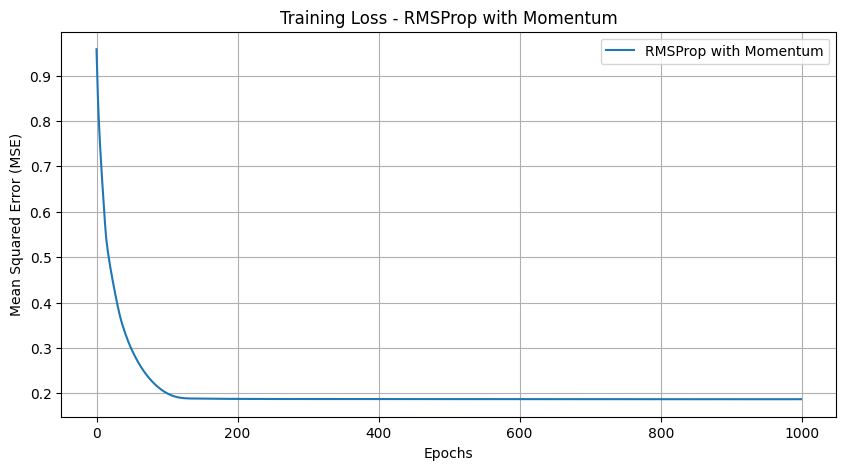

In [7]:
plt.figure(figsize=(10, 5))
plt.plot(rms_loss, label='RMSProp with Momentum')
plt.title('Training Loss - RMSProp with Momentum')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error (MSE)')
plt.legend()
plt.grid(True)
plt.show()

In [8]:

predictions_scaled = predict(
    X_test_poly, rms_weights, rms_bias
)

predictions = scaler_y.inverse_transform(predictions_scaled)
actual = scaler_y.inverse_transform(y_test_scaled)

mse = mean_squared_error(actual, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(actual, predictions)
r2 = r2_score(actual, predictions)

results = pd.DataFrame([{
    "Optimizer": "RMSProp with Momentum",
    "MSE": mse,
    "RMSE": rmse,
    "MAE": mae,
    "R2 Score": r2
}])

display(results.round(4))


,Optimizer,MSE,RMSE,MAE,R2 Score
0,RMSProp with Momentum,55.628,7.4584,5.9721,0.7841


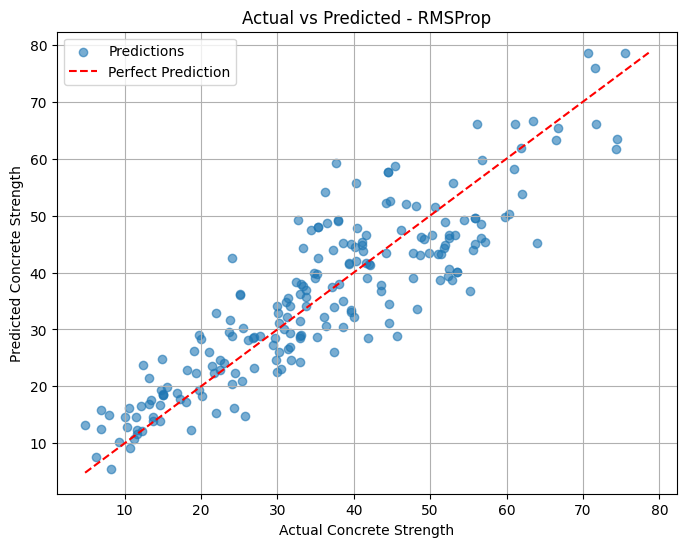

In [9]:
plt.figure(figsize=(8, 6))

plt.scatter(actual, predictions, alpha=0.6, label='Predictions')

min_value = min(actual.min(), predictions.min())
max_value = max(actual.max(), predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'r--',
    label='Perfect Prediction'
)

plt.title('Actual vs Predicted - RMSProp')
plt.xlabel('Actual Concrete Strength')
plt.ylabel('Predicted Concrete Strength')
plt.legend()
plt.grid(True)
plt.show()


### Conclusion

The RMSProp optimizer was implemented with Momentum to improve the parameter update process by combining adaptive learning rates with information from previous gradients.

The model was trained using:
- Learning Rate: 0.001
- Beta: 0.9
- Momentum: 0.9
- Epochs: 1000

The final training loss was 0.186957.

The evaluation results were:
- MSE: 55.6280
- RMSE: 7.4584
- MAE: 5.9721
- R2 Score: 0.7841

The training loss curve shows a rapid decrease followed by stable convergence.

The Actual vs Predicted plot illustrates a reasonable agreement between the actual and predicted concrete strength values.

Overall, RMSProp with Momentum achieved good predictive performance by combining adaptive gradient scaling and momentum-based updates.
